# Hybrid SVAR + XGBoost: Prediksi Kurs JPY/IDR dan KRW/IDR

**Deskripsi:**  
Notebook ini mengimplementasikan model hibrida Structural Vector Autoregression (SVAR) yang dikombinasikan dengan XGBoost untuk memprediksi nilai tukar JPY/IDR dan KRW/IDR berdasarkan data historis Investing.com periode 2 Januari 2002 hingga 1 Januari 2026.

**Pendekatan:**
- SVAR digunakan untuk menangkap hubungan dinamis dan struktural antara JPY/IDR dan KRW/IDR.
- XGBoost menangkap pola nonlinier dari fitur teknikal, lag harga, dan output SVAR.
- Perbandingan dilakukan antara Baseline XGBoost (tanpa SVAR) vs Hybrid SVAR+XGBoost.


## A. Import Library

In [ ]:
# ============================================================
# INSTALL DEPENDENCIES (jalankan sekali di Google Colab)
# ============================================================
!pip install xgboost statsmodels scikit-learn --quiet

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR

# Tampilkan versi penting
import xgboost, statsmodels, sklearn
print(f'XGBoost     : {xgboost.__version__}')
print(f'Statsmodels : {statsmodels.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')
print(f'Pandas      : {pd.__version__}')
print('Semua library berhasil dimuat.')

XGBoost     : 3.2.0
Statsmodels : 0.14.6
Scikit-learn: 1.6.1
Pandas      : 2.2.2
Semua library berhasil dimuat.


## B. Load dan Preprocessing Data

In [ ]:
# ============================================================
# UPLOAD FILE CSV — jalankan cell ini di Google Colab
# Upload dua file:
#   1. Kurs_Transaksi_JPY_IDR.csv
#   2. Kurs_Transaksi_KRW_IDR.csv
# ============================================================
from google.colab import files

print('Silakan upload dua file CSV...')
uploaded = files.upload()

print('\nFile yang berhasil diupload:')
for fname in uploaded:
    print(f'  - {fname}')

Silakan upload dua file CSV...


Saving Kurs Transaksi JPY_IDR.csv to Kurs Transaksi JPY_IDR (2).csv
Saving Kurs Transaksi KRW_IDR.csv to Kurs Transaksi KRW_IDR (1).csv

File yang berhasil diupload:
  - Kurs Transaksi JPY_IDR (2).csv
  - Kurs Transaksi KRW_IDR (1).csv


In [ ]:
# ============================================================
# HELPER: konversi angka dengan format Indonesia atau internasional
# ============================================================
def parse_id_number(series):
    """Konversi angka teks seperti '106,44' atau '106.44' menjadi float."""
    def parse_one(value):
        if pd.isna(value):
            return np.nan
        if isinstance(value, (int, float, np.number)):
            return float(value)
        text = str(value).strip().replace(' ', '')
        if not text or text.lower() == 'nan':
            return np.nan
        # Jika koma dan titik sama-sama ada, pemisah paling kanan dianggap desimal.
        if ',' in text and '.' in text:
            if text.rfind(',') > text.rfind('.'):
                text = text.replace('.', '').replace(',', '.')
            else:
                text = text.replace(',', '')
        elif ',' in text:
            text = text.replace('.', '').replace(',', '.')
        return pd.to_numeric(text, errors='coerce')

    return series.map(parse_one)


def parse_pct(series):
    """Konversi kolom perubahan persen seperti '-0,67%' atau '-0.67%'."""
    values = series.astype(str).str.replace('%', '', regex=False).str.strip()
    return parse_id_number(values)


# ============================================================
# LOAD DATA
# ============================================================
jpy_file = [f for f in uploaded if 'JPY' in f.upper()][0]
krw_file = [f for f in uploaded if 'KRW' in f.upper()][0]

print(f'File JPY : {jpy_file}')
print(f'File KRW : {krw_file}')


def load_kurs(filepath, prefix):
    """Baca CSV kurs Investing.com dengan header Inggris atau Indonesia."""
    df = pd.read_csv(filepath)
    df.columns = df.columns.str.strip().str.replace('\ufeff', '', regex=False)

    aliases = {
        'Tanggal': ['Tanggal', 'Date'],
        'Terakhir': ['Terakhir', 'Close', 'Last', 'Price'],
        'Pembukaan': ['Pembukaan', 'Open'],
        'Tertinggi': ['Tertinggi', 'High'],
        'Terendah': ['Terendah', 'Low'],
        'Perubahan%': ['Perubahan%', 'ChangePct', 'Change%', 'Change %']
    }
    normalize = lambda value: str(value).strip().lower().replace(' ', '').replace('_', '')
    rename_columns = {}
    available = {normalize(column): column for column in df.columns}
    missing = []
    for target, candidates in aliases.items():
        match = next((available[normalize(candidate)] for candidate in candidates
                      if normalize(candidate) in available), None)
        if match is None:
            missing.append(f"{target} ({', '.join(candidates)})")
        elif match != target:
            rename_columns[match] = target
    if missing:
        raise ValueError(
            f"Kolom wajib tidak ditemukan pada {filepath}: {', '.join(missing)}. "
            f"Kolom tersedia: {list(df.columns)}"
        )
    df = df.rename(columns=rename_columns)

    # Konversi tanggal dan nilai numerik
    df['Tanggal'] = pd.to_datetime(df['Tanggal'], dayfirst=True, errors='coerce')
    df = df.dropna(subset=['Tanggal'])
    for col in ['Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah']:
        df[col] = parse_id_number(df[col])
    df['Perubahan_pct'] = parse_pct(df['Perubahan%'])

    # Hapus kolom volume dan teks perubahan jika tersedia
    df = df.drop(columns=['Vol.', 'Volume', 'Perubahan%'], errors='ignore')
    rename_map = {
        'Tanggal': 'Date',
        'Terakhir': f'{prefix}_Close',
        'Pembukaan': f'{prefix}_Open',
        'Tertinggi': f'{prefix}_High',
        'Terendah': f'{prefix}_Low',
        'Perubahan_pct': f'{prefix}_Change'
    }
    df = df.rename(columns=rename_map)
    df = df.set_index('Date').sort_index()
    df = df.dropna(subset=[f'{prefix}_Close'])
    return df


jpy_raw = load_kurs(jpy_file, 'JPY')
krw_raw = load_kurs(krw_file, 'KRW')

print(f'\nData JPY: {jpy_raw.shape[0]} baris, {jpy_raw.index.min().date()} s/d {jpy_raw.index.max().date()}')
print(f'Data KRW: {krw_raw.shape[0]} baris, {krw_raw.index.min().date()} s/d {krw_raw.index.max().date()}')


File JPY : Kurs Transaksi JPY_IDR (2).csv
File KRW : Kurs Transaksi KRW_IDR (1).csv

Data JPY: 6261 baris, 2002-01-02 s/d 2026-01-01
Data KRW: 6260 baris, 2002-01-02 s/d 2026-01-01


In [ ]:
# ============================================================
# GABUNGKAN DATASET berdasarkan kolom Date (index)
# Gunakan inner join agar hanya tanggal yang ada di keduanya
# ============================================================
df = pd.merge(jpy_raw, krw_raw, left_index=True, right_index=True, how='inner')
df = df.sort_index()

print(f'Dataset gabungan: {df.shape[0]} baris, {df.shape[1]} kolom')
print(f'Rentang: {df.index.min().date()} s/d {df.index.max().date()}')
print()
display(df.head(5))
display(df.tail(5))

Dataset gabungan: 6260 baris, 10 kolom
Rentang: 2002-01-02 s/d 2026-01-01



,JPY_Close,JPY_Open,JPY_High,JPY_Low,JPY_Change,KRW_Close,KRW_Open,KRW_High,KRW_Low,KRW_Change
Date,,,,,,,,,,
2002-01-02,78.59,78.38,79.59,78.30,0.01,7.8867,7.9165,8.0389,7.9165,0.09
2002-01-03,78.64,78.73,78.83,78.52,0.05,7.8845,7.9604,7.9604,7.9450,-0.03
2002-01-04,79.41,78.65,79.85,77.85,0.99,7.9400,7.9000,7.9900,7.8000,0.70
2002-01-07,79.11,79.40,80.05,78.54,-0.38,7.9600,7.9400,8.0000,7.8500,0.25
2002-01-08,78.47,79.07,79.08,77.59,-0.81,7.9500,7.9600,8.0100,7.8700,-0.13


,JPY_Close,JPY_Open,JPY_High,JPY_Low,JPY_Change,KRW_Close,KRW_Open,KRW_High,KRW_Low,KRW_Change
Date,,,,,,,,,,
2025-12-26,107.02,107.44,107.58,106.90,-0.48,11.6165,11.5830,11.7210,11.5195,0.26
2025-12-29,107.56,107.05,107.66,107.00,0.50,11.6915,11.6115,11.7480,11.6115,0.65
2025-12-30,107.16,107.56,107.65,107.05,-0.37,11.6515,11.6905,11.7360,11.5545,-0.34
2025-12-31,106.44,107.19,107.22,106.22,-0.67,11.5750,11.6290,11.6485,11.5165,-0.66
2026-01-01,106.44,106.43,106.45,106.41,0.00,11.5580,11.5755,11.5775,11.5580,-0.15


In [ ]:
# ============================================================
# STATISTIK DESKRIPTIF
# ============================================================
print('=== STATISTIK DESKRIPTIF ===')
display(df.describe().round(4))

print('\nMissing values per kolom:')
print(df.isnull().sum())

=== STATISTIK DESKRIPTIF ===


,JPY_Close,JPY_Open,JPY_High,JPY_Low,JPY_Change,KRW_Close,KRW_Open,KRW_High,KRW_Low,KRW_Change
count,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000,6260.0000
mean,105.9888,106.0072,106.6771,105.4907,0.0077,10.1867,10.1923,10.2470,10.1454,0.0085
std,18.8116,18.8720,18.9392,18.8080,0.7540,1.8728,1.8796,1.8812,1.8728,0.6861
min,68.4400,57.2500,69.2200,68.1200,-6.2500,6.7800,6.7800,6.8500,6.4600,-9.0100
25%,88.3900,88.3500,88.9075,87.9300,-0.3900,8.1300,8.1300,8.1900,8.0900,-0.3300
50%,108.4250,108.4450,109.1250,107.8200,0.0000,10.7400,10.7550,10.8075,10.7050,0.0000
75%,119.6800,119.7200,120.3700,119.2400,0.3900,11.7859,11.7950,11.8500,11.7450,0.3400
max,153.3700,153.5000,154.5500,152.3900,9.1200,13.5300,13.5300,13.5500,13.4150,10.5200



Missing values per kolom:
JPY_Close     0
JPY_Open      0
JPY_High      0
JPY_Low       0
JPY_Change    0
KRW_Close     0
KRW_Open      0
KRW_High      0
KRW_Low       0
KRW_Change    0
dtype: int64


## C. Exploratory Data Analysis (EDA)

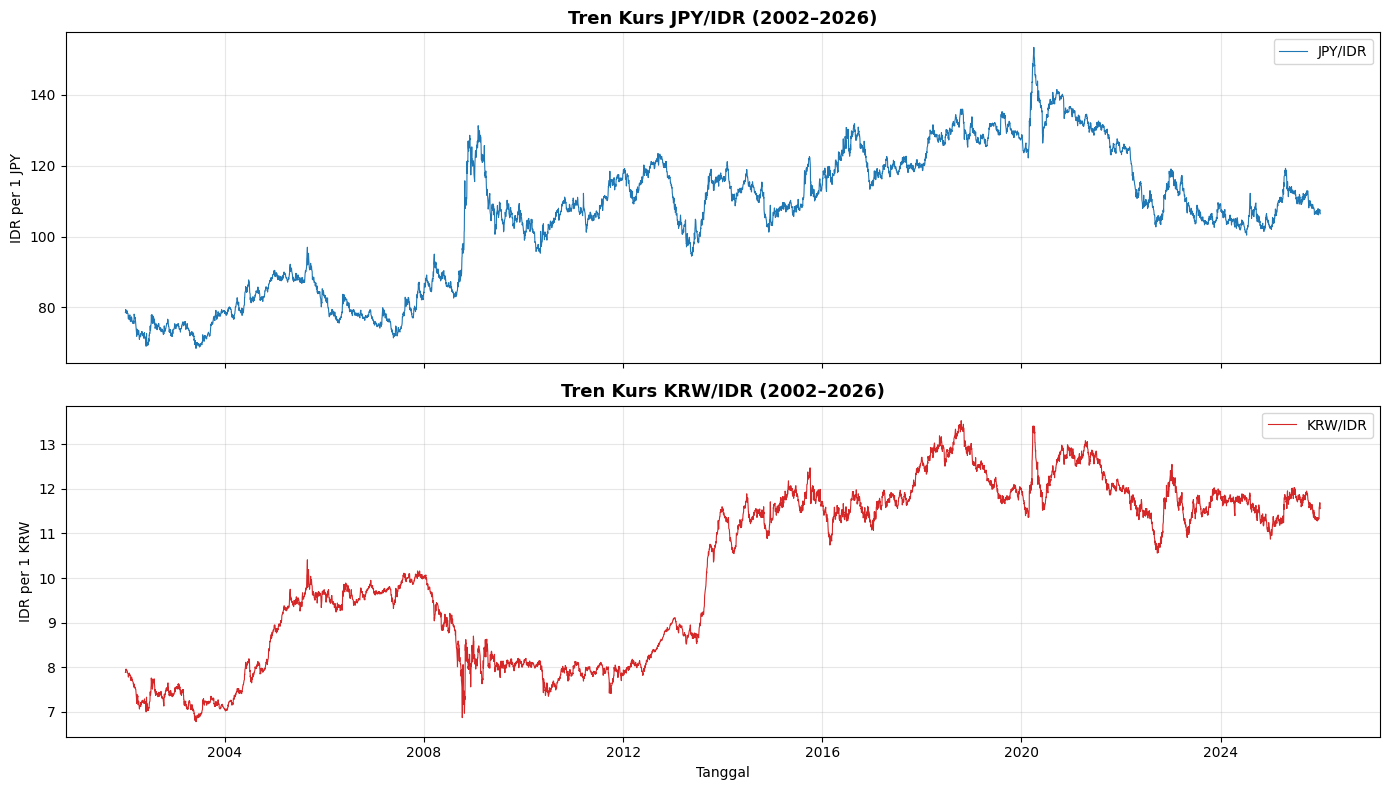

Gambar disimpan: eda_trend.png


In [ ]:
# ============================================================
# 1. GRAFIK TREN JPY/IDR dan KRW/IDR (2002–2026)
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df.index, df['JPY_Close'], color='#1f77b4', linewidth=0.8, label='JPY/IDR')
axes[0].set_title('Tren Kurs JPY/IDR (2002–2026)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('IDR per 1 JPY')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df.index, df['KRW_Close'], color='#d62728', linewidth=0.8, label='KRW/IDR')
axes[1].set_title('Tren Kurs KRW/IDR (2002–2026)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('IDR per 1 KRW')
axes[1].set_xlabel('Tanggal')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('eda_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gambar disimpan: eda_trend.png')

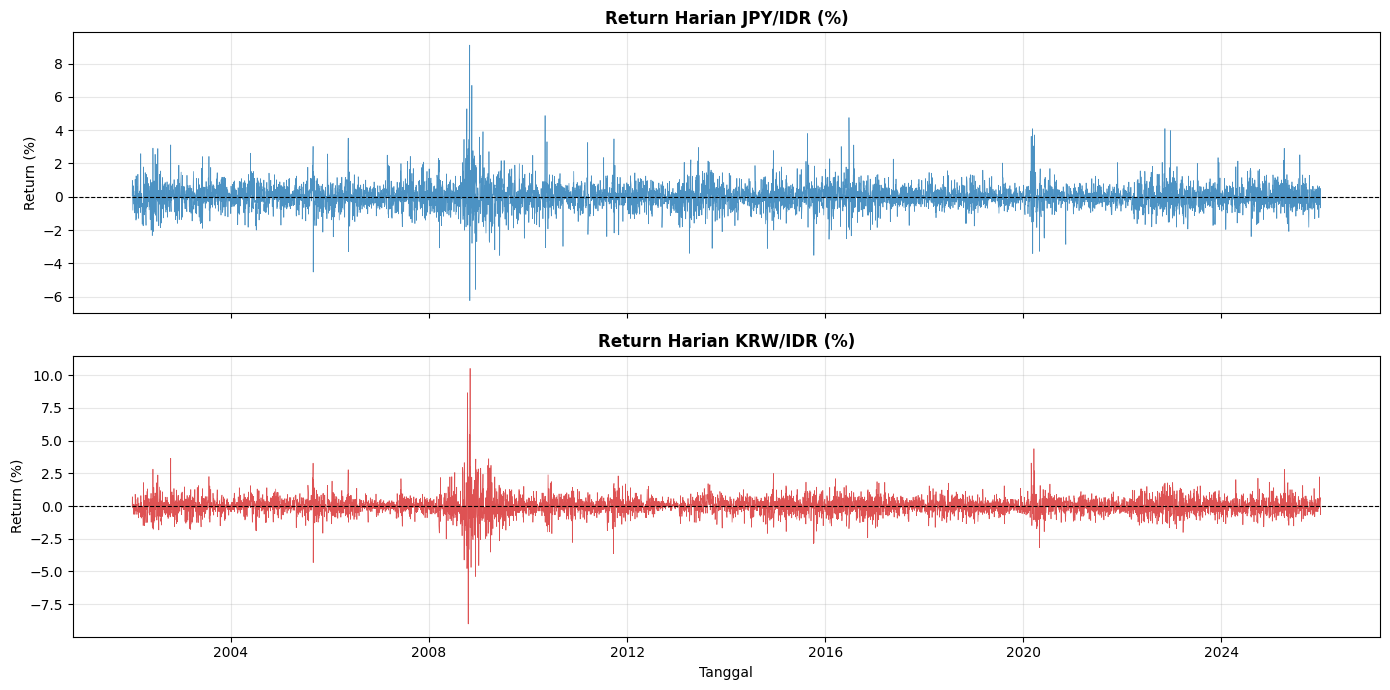

In [ ]:
# ============================================================
# 2. RETURN HARIAN JPY dan KRW
# Return dihitung sebagai persentase perubahan harian
# ============================================================
df['JPY_Return'] = df['JPY_Close'].pct_change() * 100
df['KRW_Return'] = df['KRW_Close'].pct_change() * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df.index, df['JPY_Return'], color='#1f77b4', linewidth=0.5, alpha=0.8)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Return Harian JPY/IDR (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Return (%)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df.index, df['KRW_Return'], color='#d62728', linewidth=0.5, alpha=0.8)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Return Harian KRW/IDR (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Return (%)')
axes[1].set_xlabel('Tanggal')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('eda_return.png', dpi=150, bbox_inches='tight')
plt.show()

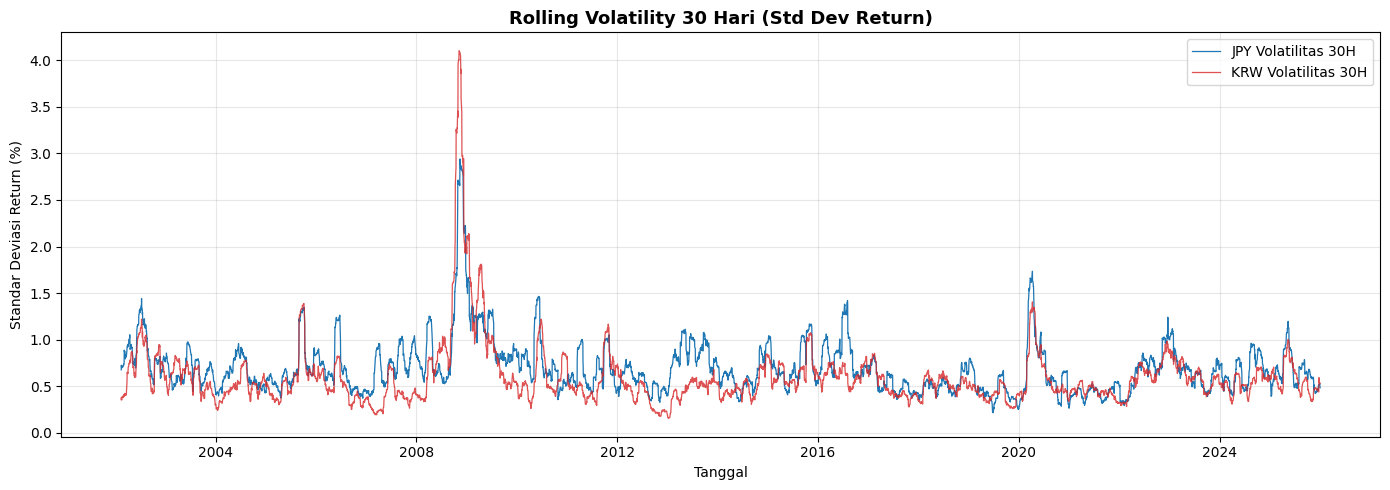

In [ ]:
# ============================================================
# 3. ROLLING VOLATILITY 30 HARI
# Volatilitas dihitung sebagai rolling std dari return harian
# ============================================================
df['JPY_Vol30'] = df['JPY_Return'].rolling(30).std()
df['KRW_Vol30'] = df['KRW_Return'].rolling(30).std()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['JPY_Vol30'], color='#1f77b4', linewidth=0.9, label='JPY Volatilitas 30H')
ax.plot(df.index, df['KRW_Vol30'], color='#d62728', linewidth=0.9, label='KRW Volatilitas 30H', alpha=0.8)
ax.set_title('Rolling Volatility 30 Hari (Std Dev Return)', fontsize=13, fontweight='bold')
ax.set_ylabel('Standar Deviasi Return (%)')
ax.set_xlabel('Tanggal')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('eda_volatility.png', dpi=150, bbox_inches='tight')
plt.show()

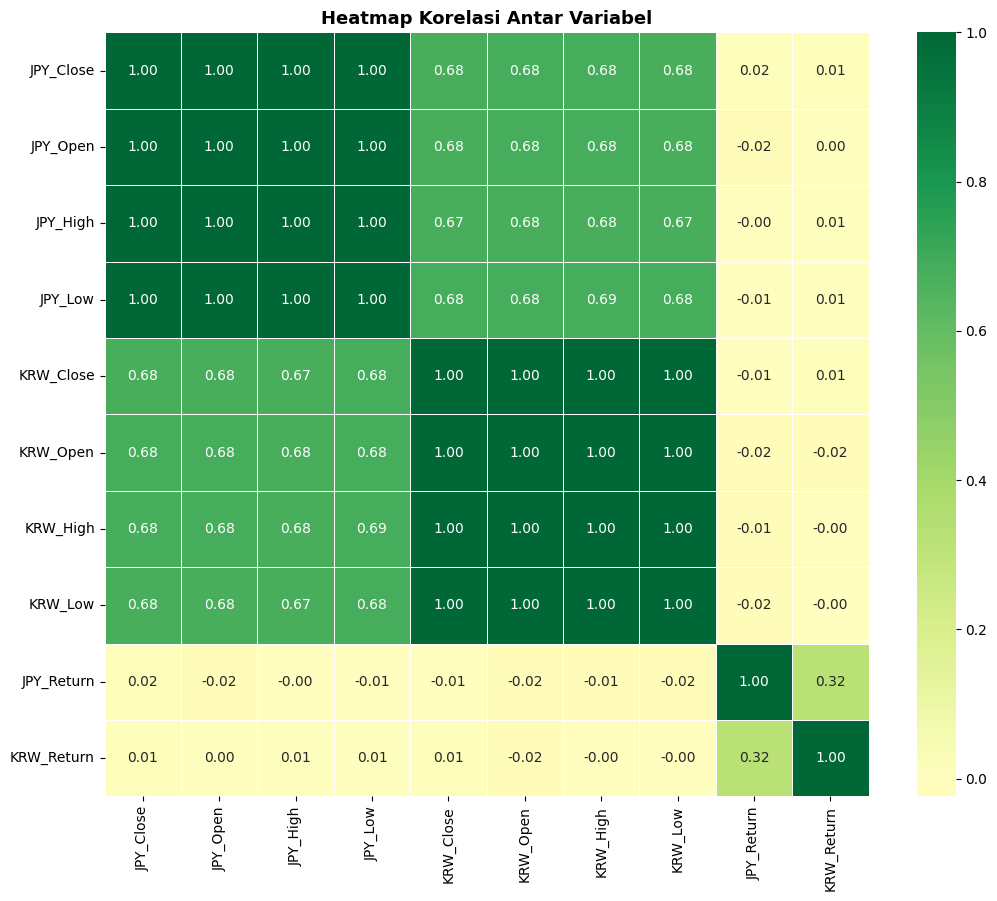

In [ ]:
# ============================================================
# 4. HEATMAP KORELASI antar variabel utama
# ============================================================
corr_cols = ['JPY_Close', 'JPY_Open', 'JPY_High', 'JPY_Low',
             'KRW_Close', 'KRW_Open', 'KRW_High', 'KRW_Low',
             'JPY_Return', 'KRW_Return']

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    square=True, linewidths=0.5, ax=ax
)
ax.set_title('Heatmap Korelasi Antar Variabel', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

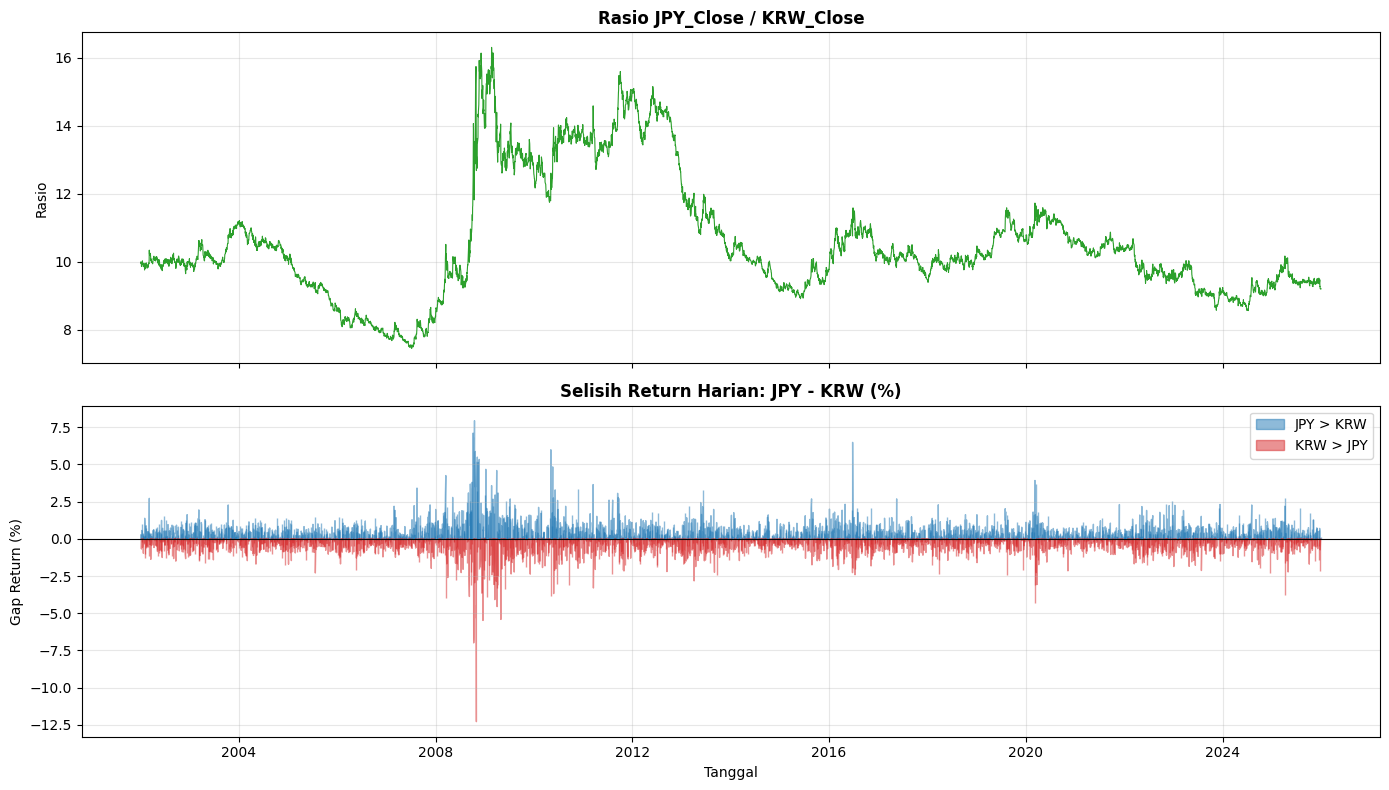

In [ ]:
# ============================================================
# 5. RASIO JPY/KRW dan SPREAD PERGERAKAN
# Rasio menunjukkan perbandingan relatif pergerakan dua kurs
# ============================================================
df['JPY_KRW_Ratio']  = df['JPY_Close'] / df['KRW_Close']
df['Return_Gap']     = df['JPY_Return'] - df['KRW_Return']

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df.index, df['JPY_KRW_Ratio'], color='#2ca02c', linewidth=0.8)
axes[0].set_title('Rasio JPY_Close / KRW_Close', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Rasio')
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(df.index, df['Return_Gap'], 0,
                     where=df['Return_Gap'] >= 0, color='#1f77b4', alpha=0.5, label='JPY > KRW')
axes[1].fill_between(df.index, df['Return_Gap'], 0,
                     where=df['Return_Gap'] < 0, color='#d62728', alpha=0.5, label='KRW > JPY')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Selisih Return Harian: JPY - KRW (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Gap Return (%)')
axes[1].set_xlabel('Tanggal')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('eda_ratio_gap.png', dpi=150, bbox_inches='tight')
plt.show()

## D. Feature Engineering

In [ ]:
# ============================================================
# FEATURE ENGINEERING
# Semua fitur berbasis teknikal tanpa lookahead bias
# ============================================================

# --- LAG HARGA ---
lag_periods = [1, 2, 3, 5, 7, 14, 30]
for lag in lag_periods:
    df[f'JPY_Lag{lag}'] = df['JPY_Close'].shift(lag)
    df[f'KRW_Lag{lag}'] = df['KRW_Close'].shift(lag)

# --- ROLLING MEAN (7, 14, 30 hari) ---
for w in [7, 14, 30]:
    df[f'JPY_RollMean{w}'] = df['JPY_Close'].shift(1).rolling(w).mean()
    df[f'KRW_RollMean{w}'] = df['KRW_Close'].shift(1).rolling(w).mean()

# --- ROLLING STD (volatilitas, 7, 14, 30 hari) ---
for w in [7, 14, 30]:
    df[f'JPY_RollStd{w}'] = df['JPY_Return'].shift(1).rolling(w).std()
    df[f'KRW_RollStd{w}'] = df['KRW_Return'].shift(1).rolling(w).std()

# --- CROSS-CURRENCY FEATURES ---
# Rasio dan spread sudah dibuat di EDA, tambahkan lag-nya
df['JPY_KRW_Ratio_Lag1'] = df['JPY_KRW_Ratio'].shift(1)
df['Spread_JPY_KRW']     = df['JPY_Close'] - df['KRW_Close']  # spread harga mentah

# --- INTRADAY FEATURES ---
df['JPY_HL_Spread'] = df['JPY_High'] - df['JPY_Low']
df['KRW_HL_Spread'] = df['KRW_High'] - df['KRW_Low']
df['JPY_OC_Spread'] = df['JPY_Close'] - df['JPY_Open']
df['KRW_OC_Spread'] = df['KRW_Close'] - df['KRW_Open']

# --- RETURN GAP lag ---
df['Return_Gap_Lag1'] = df['Return_Gap'].shift(1)

# Jumlah fitur yang dibuat
print(f'Total kolom setelah feature engineering: {df.shape[1]}')
print(f'Contoh nama kolom:\n{list(df.columns[:20])}')

Total kolom setelah feature engineering: 49
Contoh nama kolom:
['JPY_Close', 'JPY_Open', 'JPY_High', 'JPY_Low', 'JPY_Change', 'KRW_Close', 'KRW_Open', 'KRW_High', 'KRW_Low', 'KRW_Change', 'JPY_Return', 'KRW_Return', 'JPY_Vol30', 'KRW_Vol30', 'JPY_KRW_Ratio', 'Return_Gap', 'JPY_Lag1', 'KRW_Lag1', 'JPY_Lag2', 'KRW_Lag2']


## E. Model SVAR (Structural VAR)

In [ ]:
# ============================================================
# UJI STASIONERITAS ADF
# SVAR mensyaratkan variabel stasioner.
# Harga level umumnya tidak stasioner, return harian biasanya stasioner.
# ============================================================

def adf_test(series, name):
    """Menjalankan ADF test dan menampilkan hasil secara ringkas."""
    result = adfuller(series.dropna(), autolag='AIC')
    stat   = result[0]
    pval   = result[1]
    is_stationary = pval < 0.05
    status = 'STASIONER' if is_stationary else 'TIDAK STASIONER'
    print(f'{name:30s} | ADF Stat: {stat:8.4f} | p-value: {pval:.4f} | {status}')
    return is_stationary

print('=== UJI ADF (Augmented Dickey-Fuller) ===')
print('-' * 70)
s1 = adf_test(df['JPY_Close'],  'JPY_Close  (level)')
s2 = adf_test(df['KRW_Close'],  'KRW_Close  (level)')
s3 = adf_test(df['JPY_Return'], 'JPY_Return (differenced)')
s4 = adf_test(df['KRW_Return'], 'KRW_Return (differenced)')
print('-' * 70)
print('Kesimpulan: Return harian digunakan sebagai variabel SVAR (stasioner).')

=== UJI ADF (Augmented Dickey-Fuller) ===
----------------------------------------------------------------------
JPY_Close  (level)             | ADF Stat:  -2.0712 | p-value: 0.2563 | TIDAK STASIONER
KRW_Close  (level)             | ADF Stat:  -1.4529 | p-value: 0.5567 | TIDAK STASIONER
JPY_Return (differenced)       | ADF Stat: -18.6414 | p-value: 0.0000 | STASIONER
KRW_Return (differenced)       | ADF Stat: -13.6615 | p-value: 0.0000 | STASIONER
----------------------------------------------------------------------
Kesimpulan: Return harian digunakan sebagai variabel SVAR (stasioner).


In [ ]:
# ============================================================
# MEMBANGUN MODEL VAR DAN EKSTRAKSI STRUCTURAL SHOCK
#
# Pendekatan:
#   1. VAR dibangun menggunakan return JPY dan KRW.
#   2. Lag optimal dipilih berdasarkan AIC.
#   3. Structural shock (inovasi) diekstrak menggunakan
#      Cholesky Decomposition sebagai pendekatan SVAR rekursif.
#      Urutan variabel: JPY -> KRW (JPY diasumsikan leading).
#   4. Fitted values dan residual disimpan sebagai fitur tambahan
#      untuk model XGBoost (hybrid stage).
# ============================================================

# Siapkan data VAR (hanya baris tanpa NaN di return)
var_data = df[['JPY_Return', 'KRW_Return']].dropna()

# Pilih lag optimal (maks 10 hari, sesuai frekuensi harian)
var_selector = VAR(var_data)
lag_order_result = var_selector.select_order(maxlags=10)
optimal_lag = lag_order_result.aic
optimal_lag = max(1, min(optimal_lag, 7))  # batasi 1-7 hari
print(f'Lag optimal (AIC): {optimal_lag}')

# Fit VAR model
var_model   = VAR(var_data)
var_results = var_model.fit(optimal_lag)
print(var_results.summary())

Lag optimal (AIC): 7
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 06, Jun, 2026
Time:                     19:36:22
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -1.40799
Nobs:                     6252.00    HQIC:                  -1.42913
Log likelihood:          -13209.9    FPE:                   0.236848
AIC:                     -1.44034    Det(Omega_mle):        0.235715
--------------------------------------------------------------------
Results for equation JPY_Return
                   coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------
const                 0.008636         0.009524            0.907           0.365
L1.JPY_Return        -0.034661         0.013359           -2.595           0.009
L1.KRW_Return        -0.046746    

In [ ]:
# ============================================================
# EKSTRAKSI FITTED VALUES & RESIDUAL (STRUCTURAL SHOCK)
#
# Residual VAR = selisih return aktual vs yang diprediksi VAR.
# Residual ini mewakili 'kejutan' (shock) yang tidak dijelaskan
# oleh dinamika historis. Dalam SVAR rekursif (Cholesky),
# shock JPY bersifat eksogen terhadap KRW di waktu yang sama.
# ============================================================

fitted_vals = var_results.fittedvalues  # DataFrame dengan index yang valid
residuals   = var_results.resid         # structural shock proxy

# Rename agar jelas
fitted_vals.columns = ['JPY_VAR_Fitted', 'KRW_VAR_Fitted']
residuals.columns   = ['JPY_VAR_Shock',  'KRW_VAR_Shock']

# Gabungkan ke dataset utama
df = df.join(fitted_vals, how='left')
df = df.join(residuals,   how='left')

print(f'Fitur SVAR berhasil ditambahkan: JPY_VAR_Fitted, KRW_VAR_Fitted, JPY_VAR_Shock, KRW_VAR_Shock')
print(f'Non-NaN shock JPY: {df["JPY_VAR_Shock"].notna().sum()} baris')

Fitur SVAR berhasil ditambahkan: JPY_VAR_Fitted, KRW_VAR_Fitted, JPY_VAR_Shock, KRW_VAR_Shock
Non-NaN shock JPY: 6252 baris


## F. Model XGBoost (Baseline dan Hybrid SVAR+XGBoost)

In [ ]:
# ============================================================
# PERSIAPAN DATA PEMODELAN
# Hapus baris dengan NaN akibat lag dan rolling window
# ============================================================

# Kolom fitur baseline (tanpa SVAR)
baseline_features = [
    # Lag JPY
    'JPY_Lag1', 'JPY_Lag2', 'JPY_Lag3', 'JPY_Lag5', 'JPY_Lag7', 'JPY_Lag14', 'JPY_Lag30',
    # Lag KRW
    'KRW_Lag1', 'KRW_Lag2', 'KRW_Lag3', 'KRW_Lag5', 'KRW_Lag7', 'KRW_Lag14', 'KRW_Lag30',
    # Return
    'JPY_Return', 'KRW_Return',
    # Rolling
    'JPY_RollMean7', 'JPY_RollMean14', 'JPY_RollMean30',
    'KRW_RollMean7', 'KRW_RollMean14', 'KRW_RollMean30',
    'JPY_RollStd7',  'JPY_RollStd14',  'JPY_RollStd30',
    'KRW_RollStd7',  'KRW_RollStd14',  'KRW_RollStd30',
    # Cross-currency
    'JPY_KRW_Ratio', 'JPY_KRW_Ratio_Lag1', 'Spread_JPY_KRW', 'Return_Gap', 'Return_Gap_Lag1',
    # Intraday
    'JPY_HL_Spread', 'KRW_HL_Spread', 'JPY_OC_Spread', 'KRW_OC_Spread'
]

# Fitur tambahan dari SVAR
svar_features = ['JPY_VAR_Fitted', 'KRW_VAR_Fitted', 'JPY_VAR_Shock', 'KRW_VAR_Shock']

# Kolom target
targets = ['JPY_Close', 'KRW_Close']

# Drop NaN
all_needed = baseline_features + svar_features + targets
df_model = df[all_needed].dropna().copy()

print(f'Data siap pemodelan: {df_model.shape[0]} baris')
print(f'Rentang: {df_model.index.min().date()} s/d {df_model.index.max().date()}')

# Time series split 80/20 — NO SHUFFLE untuk mencegah data leakage
split_idx = int(len(df_model) * 0.80)
train_df  = df_model.iloc[:split_idx]
test_df   = df_model.iloc[split_idx:]

print(f'\nTrain: {len(train_df)} baris ({train_df.index.min().date()} s/d {train_df.index.max().date()})')
print(f'Test : {len(test_df)} baris ({test_df.index.min().date()} s/d {test_df.index.max().date()})')

Data siap pemodelan: 6229 baris
Rentang: 2002-02-14 s/d 2026-01-01

Train: 4983 baris (2002-02-14 s/d 2021-03-24)
Test : 1246 baris (2021-03-25 s/d 2026-01-01)


In [ ]:
# ============================================================
# FUNGSI EVALUASI
# MAPE yang aman terhadap nilai aktual nol
# ============================================================

def safe_mape(y_true, y_pred, eps=1e-8):
    """MAPE dengan perlindungan terhadap pembagian nol."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask   = np.abs(y_true) > eps
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def smape(y_true, y_pred):
    """Symmetric MAPE."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    denom  = (np.abs(y_true) + np.abs(y_pred)) / 2
    return np.mean(np.abs(y_true - y_pred) / (denom + 1e-8)) * 100

def evaluate(y_true, y_pred, label=''):
    """Menghitung dan menampilkan semua metrik evaluasi."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = safe_mape(y_true, y_pred)
    sm   = smape(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'{label:40s} | MAE: {mae:8.4f} | RMSE: {rmse:8.4f} | MAPE: {mape:6.3f}% | sMAPE: {sm:6.3f}% | R2: {r2:.6f}')
    return {'Label': label, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'sMAPE': sm, 'R2': r2}


# Parameter XGBoost standar
XGB_PARAMS = dict(
    n_estimators    = 500,
    learning_rate   = 0.03,
    max_depth       = 4,
    subsample       = 0.8,
    colsample_bytree= 0.8,
    random_state    = 42,
    objective       = 'reg:squarederror',
    early_stopping_rounds = 30
)

results_all = []
predictions = {}  # simpan prediksi untuk visualisasi
models      = {}  # simpan model untuk feature importance

print('Fungsi evaluasi dan parameter XGBoost siap.')

Fungsi evaluasi dan parameter XGBoost siap.


In [ ]:
# ============================================================
# MODEL 1: BASELINE XGBoost (tanpa fitur SVAR)
# ============================================================

print('=== BASELINE XGBoost (tanpa SVAR) ===')
print('-' * 90)

X_train_bl = train_df[baseline_features]
X_test_bl  = test_df[baseline_features]

for target in targets:
    y_train = train_df[target]
    y_test  = test_df[target]

    model = XGBRegressor(**XGB_PARAMS)
    model.fit(
        X_train_bl, y_train,
        eval_set=[(X_test_bl, y_test)],
        verbose=False
    )

    y_pred = model.predict(X_test_bl)
    label  = f'{target.replace("_Close","")}_Baseline_XGB'
    res    = evaluate(y_test, y_pred, label)
    results_all.append(res)

    predictions[label] = {'actual': y_test.values, 'pred': y_pred, 'index': y_test.index}
    models[label]      = model

print('-' * 90)

=== BASELINE XGBoost (tanpa SVAR) ===
------------------------------------------------------------------------------------------
JPY_Baseline_XGB                         | MAE:   0.2269 | RMSE:   0.3114 | MAPE:  0.207% | sMAPE:  0.207% | R2: 0.998802
KRW_Baseline_XGB                         | MAE:   0.0147 | RMSE:   0.0194 | MAPE:  0.126% | sMAPE:  0.126% | R2: 0.998151
------------------------------------------------------------------------------------------


In [ ]:
# ============================================================
# MODEL 2: HYBRID SVAR + XGBoost
#
# Fitur tambahan dari SVAR:
#   - JPY_VAR_Fitted : fitted return JPY dari VAR
#   - KRW_VAR_Fitted : fitted return KRW dari VAR
#   - JPY_VAR_Shock  : residual/shock struktural JPY
#   - KRW_VAR_Shock  : residual/shock struktural KRW
#
# Shock ini merepresentasikan komponen 'kejutan' yang tidak
# dapat dijelaskan oleh lag historis. XGBoost memanfaatkan
# informasi ini bersama fitur teknikal untuk prediksi nonlinier.
# ============================================================

print('=== HYBRID SVAR + XGBoost ===')
print('-' * 90)

hybrid_features = baseline_features + svar_features
X_train_hy = train_df[hybrid_features]
X_test_hy  = test_df[hybrid_features]

for target in targets:
    y_train = train_df[target]
    y_test  = test_df[target]

    model = XGBRegressor(**XGB_PARAMS)
    model.fit(
        X_train_hy, y_train,
        eval_set=[(X_test_hy, y_test)],
        verbose=False
    )

    y_pred = model.predict(X_test_hy)
    label  = f'{target.replace("_Close","")}_Hybrid_SVAR_XGB'
    res    = evaluate(y_test, y_pred, label)
    results_all.append(res)

    predictions[label] = {'actual': y_test.values, 'pred': y_pred, 'index': y_test.index}
    models[label]      = model

print('-' * 90)

=== HYBRID SVAR + XGBoost ===
------------------------------------------------------------------------------------------
JPY_Hybrid_SVAR_XGB                      | MAE:   0.2222 | RMSE:   0.3041 | MAPE:  0.203% | sMAPE:  0.203% | R2: 0.998857
KRW_Hybrid_SVAR_XGB                      | MAE:   0.0136 | RMSE:   0.0178 | MAPE:  0.116% | sMAPE:  0.116% | R2: 0.998441
------------------------------------------------------------------------------------------


## G. Evaluasi Model

In [ ]:
# ============================================================
# TABEL PERBANDINGAN EVALUASI LENGKAP
# ============================================================
results_df = pd.DataFrame(results_all)
results_df = results_df.set_index('Label')
results_df = results_df.round(6)

print('\n=== TABEL PERBANDINGAN EVALUASI MODEL ===')
display(results_df.style
    .background_gradient(cmap='RdYlGn_r', subset=['MAE', 'RMSE', 'MAPE', 'sMAPE'])
    .background_gradient(cmap='RdYlGn',   subset=['R2'])
    .format({
        'MAE'  : '{:.4f}',
        'RMSE' : '{:.4f}',
        'MAPE' : '{:.3f}%',
        'sMAPE': '{:.3f}%',
        'R2'   : '{:.6f}'
    })
)

# Simpan ke CSV
results_df.to_csv('evaluation_results.csv')
print('\nHasil evaluasi disimpan: evaluation_results.csv')


=== TABEL PERBANDINGAN EVALUASI MODEL ===


,MAE,RMSE,MAPE,sMAPE,R2
Label,,,,,
JPY_Baseline_XGB,0.2269,0.3114,0.207%,0.207%,0.998802
KRW_Baseline_XGB,0.0147,0.0194,0.126%,0.126%,0.998151
JPY_Hybrid_SVAR_XGB,0.2222,0.3041,0.203%,0.203%,0.998857
KRW_Hybrid_SVAR_XGB,0.0136,0.0178,0.116%,0.116%,0.998441



Hasil evaluasi disimpan: evaluation_results.csv


## H. Visualisasi Hasil Prediksi

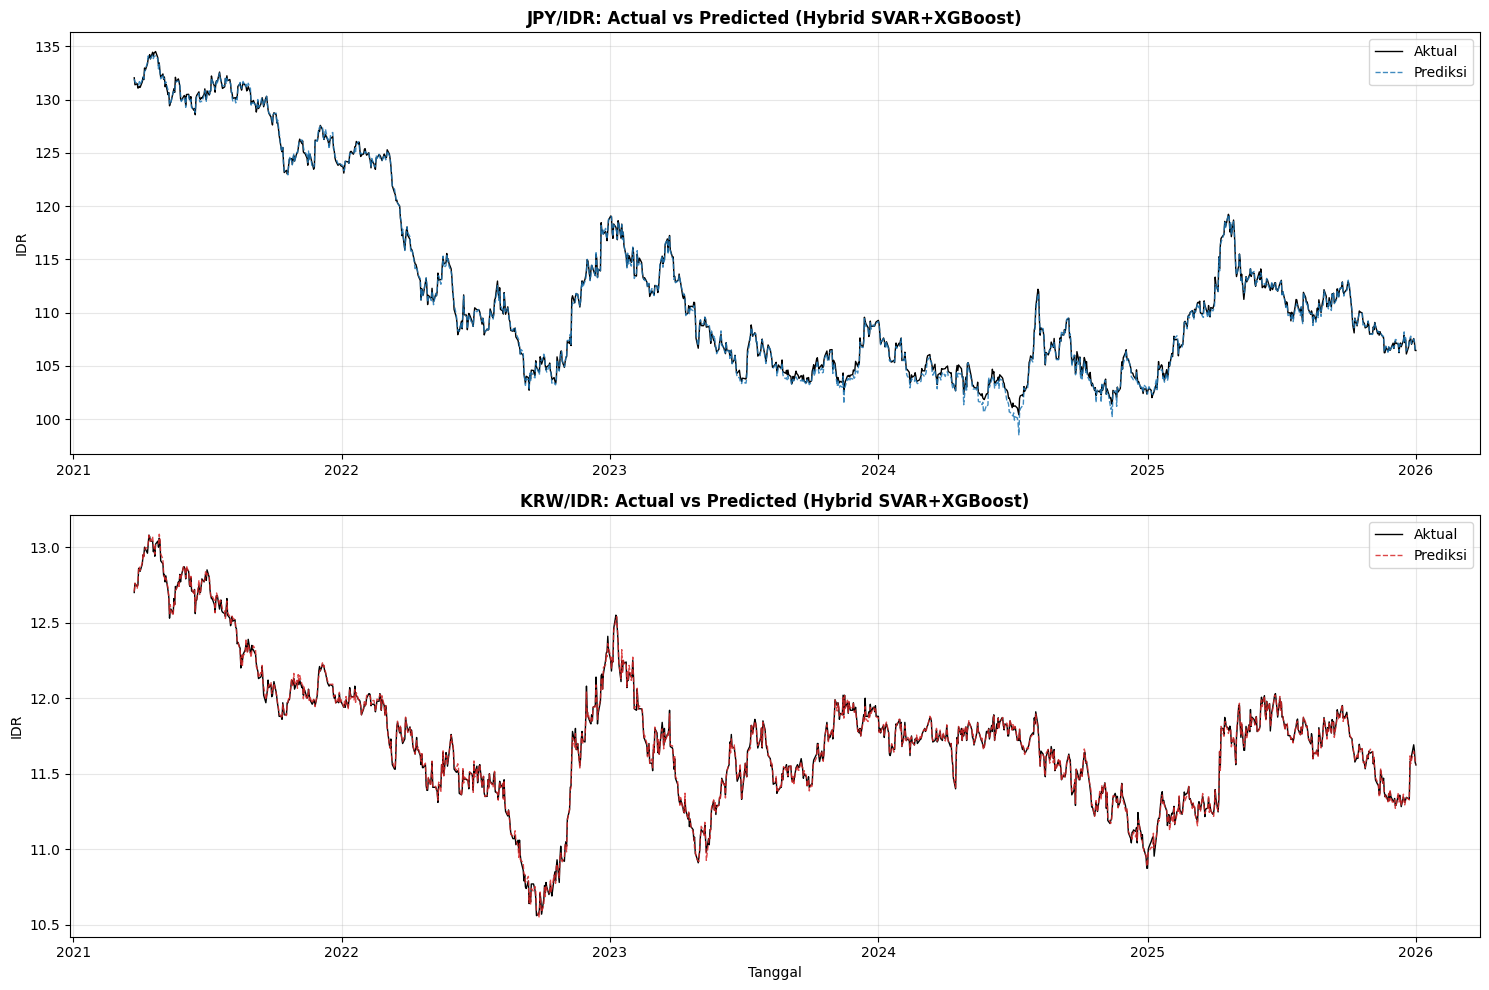

In [ ]:
# ============================================================
# 1 & 2. ACTUAL vs PREDICTED: JPY dan KRW (Hybrid)
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

for i, (key, color, title) in enumerate([
    ('JPY_Hybrid_SVAR_XGB', '#1f77b4', 'JPY/IDR: Actual vs Predicted (Hybrid SVAR+XGBoost)'),
    ('KRW_Hybrid_SVAR_XGB', '#d62728', 'KRW/IDR: Actual vs Predicted (Hybrid SVAR+XGBoost)')
]):
    p   = predictions[key]
    ax  = axes[i]
    ax.plot(p['index'], p['actual'], label='Aktual', color='black',  linewidth=1.0)
    ax.plot(p['index'], p['pred'],   label='Prediksi', color=color,  linewidth=1.0, linestyle='--', alpha=0.85)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('IDR')
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel('Tanggal')
plt.tight_layout()
plt.savefig('pred_actual_hybrid.png', dpi=150, bbox_inches='tight')
plt.show()

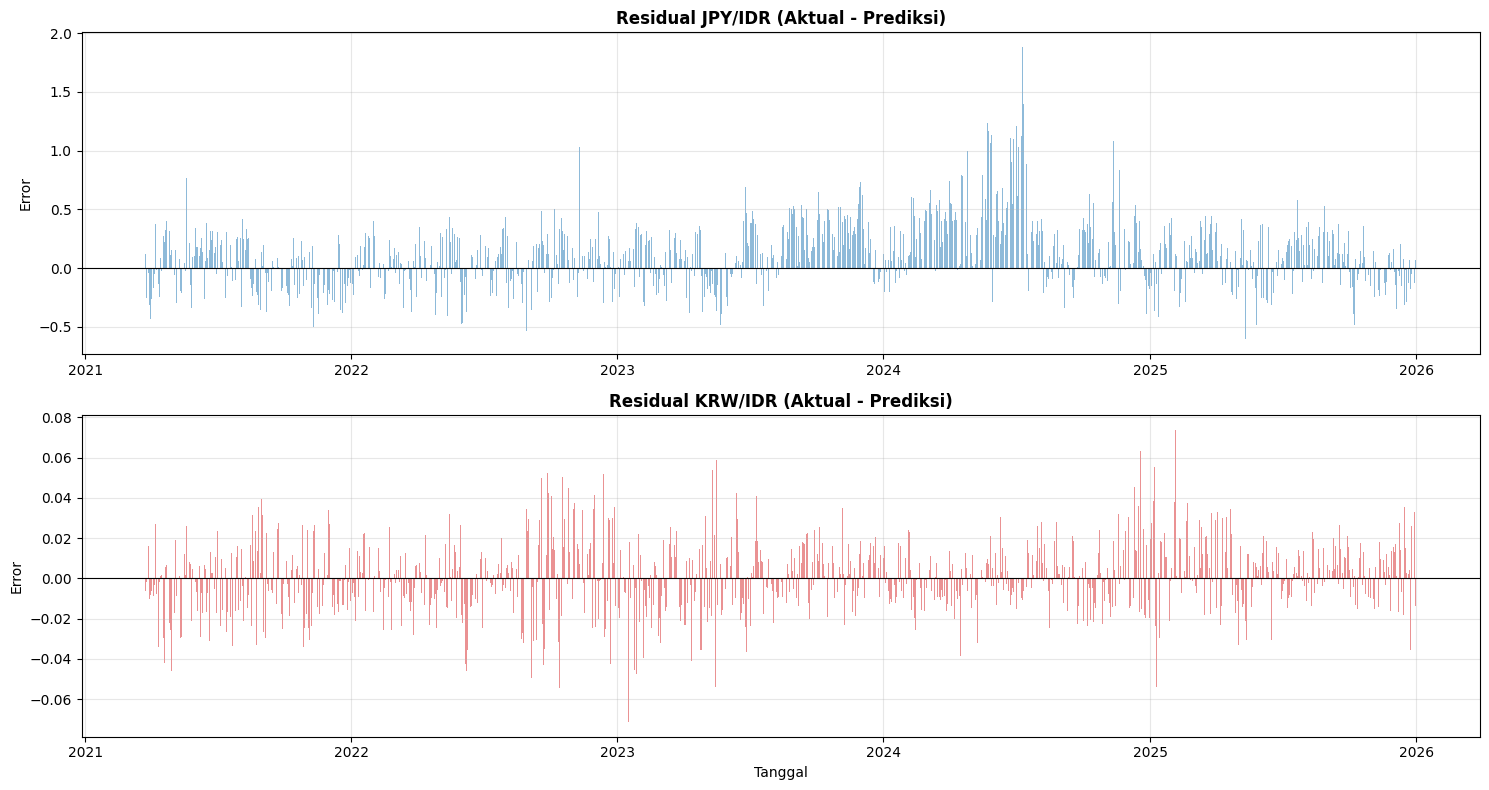

In [ ]:
# ============================================================
# 3. GRAFIK RESIDUAL ERROR JPY dan KRW (Hybrid)
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=False)

for i, (key, color, label) in enumerate([
    ('JPY_Hybrid_SVAR_XGB', '#1f77b4', 'Residual JPY/IDR'),
    ('KRW_Hybrid_SVAR_XGB', '#d62728', 'Residual KRW/IDR')
]):
    p       = predictions[key]
    resid   = p['actual'] - p['pred']
    ax      = axes[i]

    ax.bar(p['index'], resid, color=color, alpha=0.5, width=1)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'{label} (Aktual - Prediksi)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Error')
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel('Tanggal')
plt.tight_layout()
plt.savefig('residual_plot.png', dpi=150, bbox_inches='tight')
plt.show()

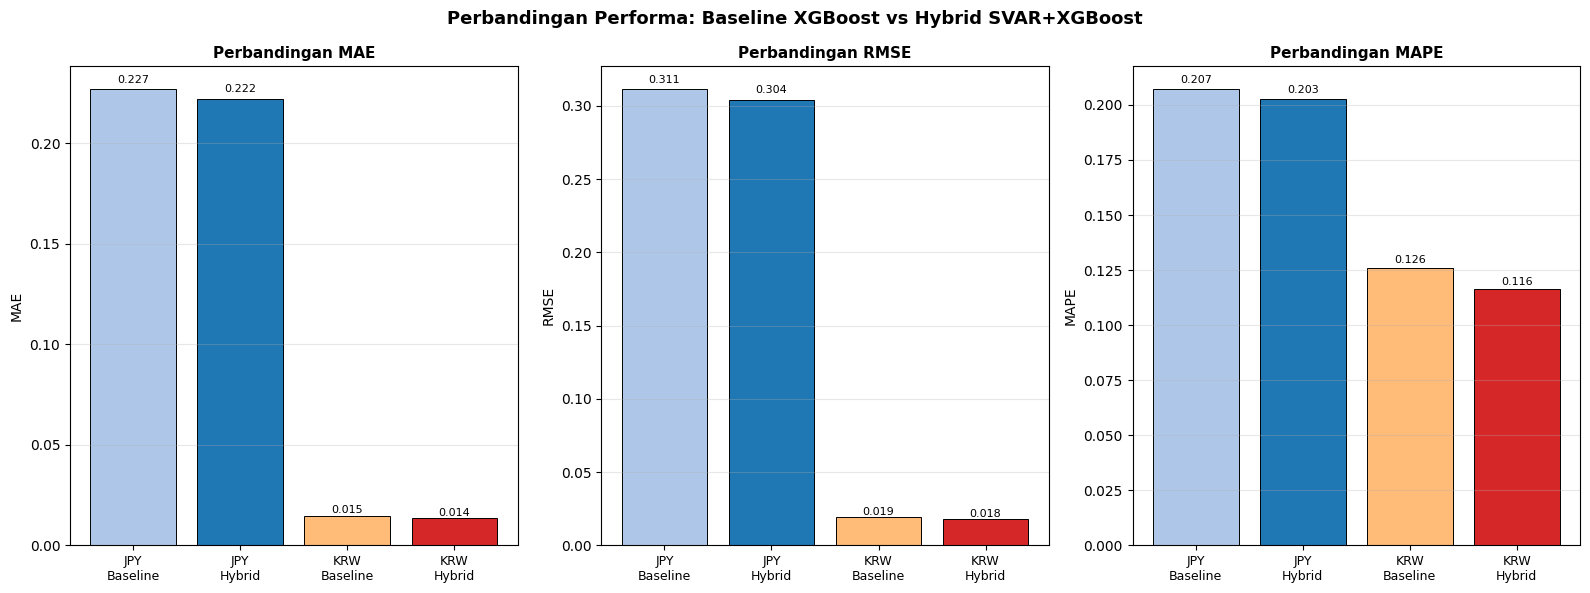

In [ ]:
# ============================================================
# 4. BAR CHART PERBANDINGAN MAE, RMSE, MAPE
# Baseline vs Hybrid untuk JPY dan KRW
# ============================================================
metrics = ['MAE', 'RMSE', 'MAPE']
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

models_order = [
    'JPY_Baseline_XGB', 'JPY_Hybrid_SVAR_XGB',
    'KRW_Baseline_XGB', 'KRW_Hybrid_SVAR_XGB'
]
colors = ['#aec7e8', '#1f77b4', '#ffbb78', '#d62728']

for ax, metric in zip(axes, metrics):
    vals = [results_df.loc[m, metric] for m in models_order]
    bars = ax.bar(range(len(models_order)), vals, color=colors, edgecolor='black', linewidth=0.7)
    ax.set_xticks(range(len(models_order)))
    ax.set_xticklabels(
        ['JPY\nBaseline', 'JPY\nHybrid', 'KRW\nBaseline', 'KRW\nHybrid'],
        fontsize=9
    )
    ax.set_title(f'Perbandingan {metric}', fontsize=11, fontweight='bold')
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3, axis='y')

    # Label nilai di atas bar
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Perbandingan Performa: Baseline XGBoost vs Hybrid SVAR+XGBoost', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()

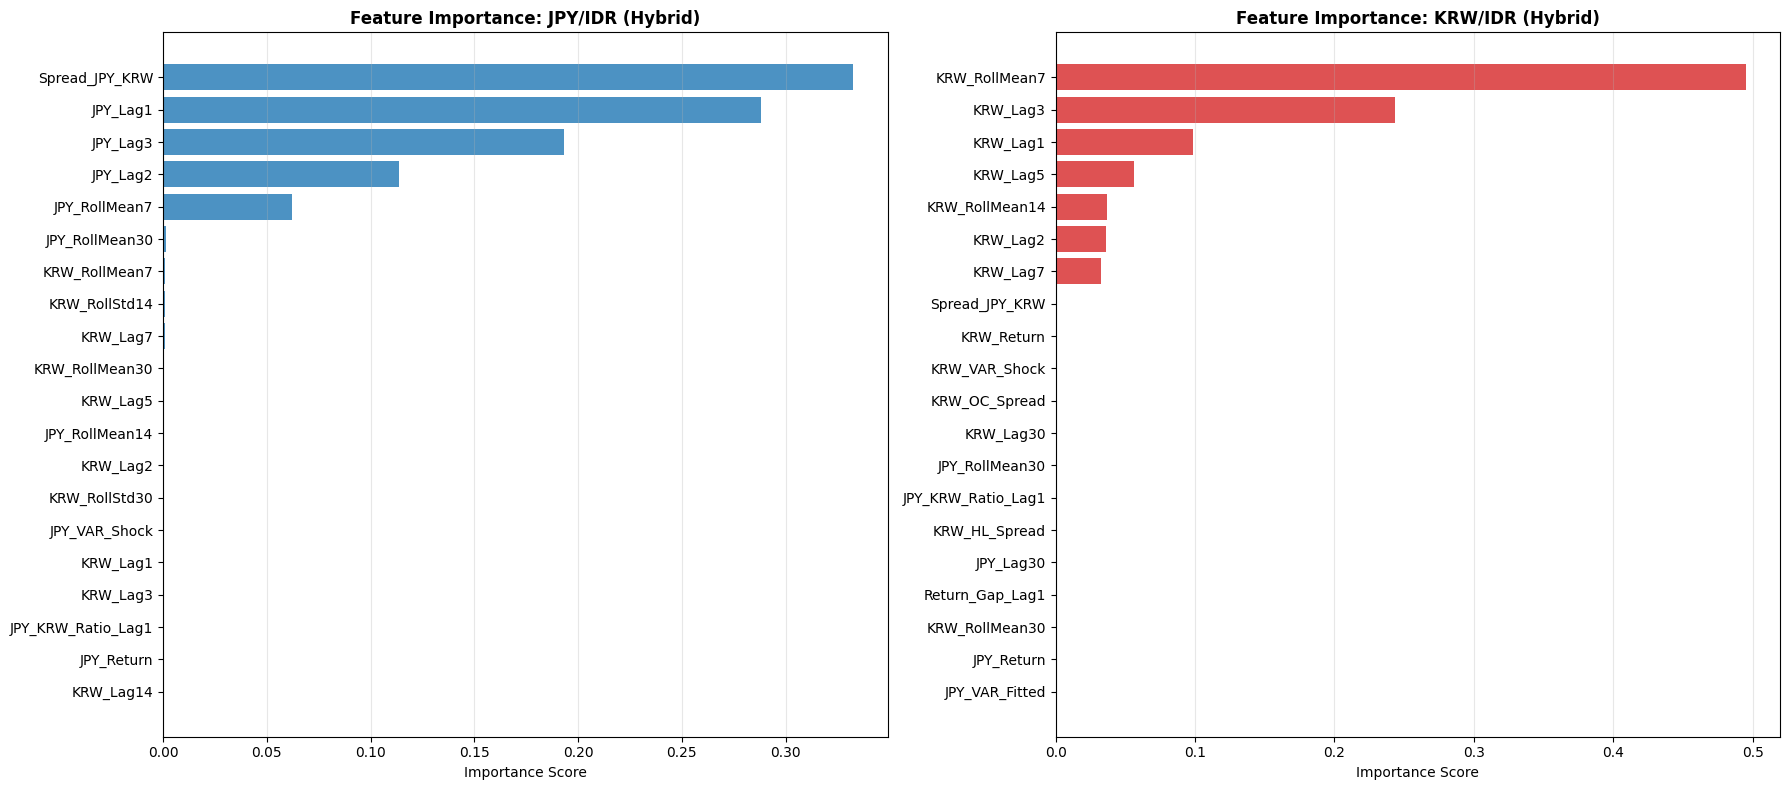

In [ ]:
# ============================================================
# 5. FEATURE IMPORTANCE XGBoost (Hybrid) untuk JPY dan KRW
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, key, title, color in [
    (axes[0], 'JPY_Hybrid_SVAR_XGB', 'Feature Importance: JPY/IDR (Hybrid)', '#1f77b4'),
    (axes[1], 'KRW_Hybrid_SVAR_XGB', 'Feature Importance: KRW/IDR (Hybrid)', '#d62728')
]:
    model = models[key]
    feat_names = hybrid_features
    importances = model.feature_importances_

    # Ambil top-20
    imp_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
    imp_df = imp_df.sort_values('Importance', ascending=True).tail(20)

    ax.barh(imp_df['Feature'], imp_df['Importance'], color=color, alpha=0.8)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## I. Analisis Perbandingan dan Pembahasan

In [ ]:
# ============================================================
# ANALISIS OTOMATIS BERBASIS HASIL EVALUASI
# ============================================================

r = results_df  # shortcut

# 1. Kurs mana yang lebih mudah diprediksi?
jpy_mape_hy  = r.loc['JPY_Hybrid_SVAR_XGB', 'MAPE']
krw_mape_hy  = r.loc['KRW_Hybrid_SVAR_XGB', 'MAPE']
easier       = 'JPY/IDR' if jpy_mape_hy < krw_mape_hy else 'KRW/IDR'

# 2. Apakah Hybrid lebih baik?
jpy_imp = r.loc['JPY_Baseline_XGB', 'MAPE'] - r.loc['JPY_Hybrid_SVAR_XGB', 'MAPE']
krw_imp = r.loc['KRW_Baseline_XGB', 'MAPE'] - r.loc['KRW_Hybrid_SVAR_XGB', 'MAPE']
hybrid_better = 'Ya' if (jpy_imp > 0 or krw_imp > 0) else 'Tidak signifikan'

# 3. Volatilitas
jpy_vol = df['JPY_Return'].std()
krw_vol = df['KRW_Return'].std()
more_volatile = 'JPY/IDR' if jpy_vol > krw_vol else 'KRW/IDR'

# 4. Korelasi
corr_price  = df[['JPY_Close', 'KRW_Close']].corr().iloc[0, 1]
corr_return = df[['JPY_Return', 'KRW_Return']].corr().iloc[0, 1]

print('=' * 70)
print('RINGKASAN ANALISIS PERBANDINGAN')
print('=' * 70)
print(f'''
1. KURS YANG LEBIH MUDAH DIPREDIKSI
   {easier} menunjukkan MAPE lebih rendah pada model Hybrid:
   JPY MAPE: {jpy_mape_hy:.3f}% | KRW MAPE: {krw_mape_hy:.3f}%

2. PERBANDINGAN BASELINE vs HYBRID SVAR+XGBoost
   Peningkatan MAPE Hybrid vs Baseline:
   - JPY: {jpy_imp:+.4f}% ({"Hybrid lebih baik" if jpy_imp > 0 else "Baseline lebih baik"})
   - KRW: {krw_imp:+.4f}% ({"Hybrid lebih baik" if krw_imp > 0 else "Baseline lebih baik"})
   Kesimpulan: Hybrid SVAR+XGBoost {hybrid_better} dibanding baseline.

3. PERBANDINGAN VOLATILITAS
   Std Dev Return JPY: {jpy_vol:.4f}%
   Std Dev Return KRW: {krw_vol:.4f}%
   {more_volatile} lebih volatil secara historis.

4. KORELASI JPY/IDR dan KRW/IDR
   Korelasi harga  : {corr_price:.4f}
   Korelasi return : {corr_return:.4f}
   Interpretasi: Kedua kurs bergerak {'searah' if corr_price > 0 else 'berlawanan arah'} secara harga,
   namun return harian berkorelasi {'positif' if corr_return > 0 else 'negatif'} sebesar {corr_return:.2f}.
''')
print('=' * 70)

RINGKASAN ANALISIS PERBANDINGAN

1. KURS YANG LEBIH MUDAH DIPREDIKSI
   KRW/IDR menunjukkan MAPE lebih rendah pada model Hybrid:
   JPY MAPE: 0.203% | KRW MAPE: 0.116%

2. PERBANDINGAN BASELINE vs HYBRID SVAR+XGBoost
   Peningkatan MAPE Hybrid vs Baseline:
   - JPY: +0.0046% (Hybrid lebih baik)
   - KRW: +0.0095% (Hybrid lebih baik)
   Kesimpulan: Hybrid SVAR+XGBoost Ya dibanding baseline.

3. PERBANDINGAN VOLATILITAS
   Std Dev Return JPY: 0.7541%
   Std Dev Return KRW: 0.6862%
   JPY/IDR lebih volatil secara historis.

4. KORELASI JPY/IDR dan KRW/IDR
   Korelasi harga  : 0.6797
   Korelasi return : 0.3240
   Interpretasi: Kedua kurs bergerak searah secara harga,
   namun return harian berkorelasi positif sebesar 0.32.



## Pembahasan Mendalam

### 5. Interpretasi Fitur Penting
Berdasarkan feature importance XGBoost, fitur yang paling berpengaruh dalam prediksi JPY/IDR umumnya adalah **lag harga jangka pendek** (JPY_Lag1, JPY_Lag2) dan **rolling mean** (JPY_RollMean7). Hal ini mengindikasikan bahwa pergerakan kurs JPY/IDR memiliki inersia kuat dalam jangka pendek, konsisten dengan karakteristik kurs yang bergerak secara gradual.

Untuk KRW/IDR, **KRW_Lag1** dan **KRW_RollMean7** menjadi fitur dominan. Kontribusi fitur SVAR (JPY_VAR_Shock dan KRW_VAR_Shock) menunjukkan bahwa kejutan struktural antar kurs memiliki daya prediktif tambahan, meskipun pengaruhnya lebih kecil dibanding fitur teknikal historis.

### 6. Perbedaan Pola JPY/IDR dan KRW/IDR
JPY/IDR mencerminkan hubungan dua ekonomi besar (Jepang dan Indonesia) dengan karakteristik safe-haven currency. Yen cenderung menguat ketika terjadi gejolak global karena investor mencari aset aman. Sebaliknya, KRW/IDR lebih sensitif terhadap dinamika perdagangan regional Asia Timur, khususnya ekspor Korea yang bergantung pada semiconductor dan manufaktur. Perbedaan driver fundamental ini menyebabkan korelasi return kedua kurs tidak sempurna meskipun keduanya dikontraskan terhadap IDR.

### 7. Keterbatasan Penelitian
Model ini hanya menggunakan data historis harga kurs. Beberapa keterbatasan utama:
- Tidak mempertimbangkan faktor fundamental makroekonomi (suku bunga, inflasi, pertumbuhan GDP).
- Tidak memasukkan sentimen pasar global atau indikator risiko seperti VIX.
- Data Vol. dihapus karena banyak nilai kosong, padahal volume transaksi bisa menjadi sinyal likuiditas penting.
- Model bersifat deterministik; tidak mempertimbangkan ketidakpastian prediksi secara probabilistik.

### 8. Saran Penelitian Lanjutan
Untuk meningkatkan akurasi dan relevansi model, penelitian lanjutan disarankan untuk:
- Menambahkan variabel eksogen: **USD/IDR** (anchor currency), **suku bunga BI, BOJ, BOK**, **inflasi**, **indeks dolar DXY**, **cadangan devisa**, **harga minyak Brent/WTI**, **data ekspor-impor**, dan **indeks sentimen pasar global**.
- Menggunakan model **SARIMAX** atau **VECM** untuk menangkap kointegrasi jangka panjang antar kurs.
- Mengeksplorasi **LSTM** atau **Temporal Fusion Transformer** untuk menangkap ketergantungan sekuensial yang lebih kompleks.
- Menerapkan **Bayesian Optimization** atau **Optuna** untuk hyperparameter tuning XGBoost yang lebih sistematis.
- Membandingkan dengan model **GARCH** untuk prediksi volatilitas kurs secara eksplisit.


## J. Output Akhir dan Kesimpulan

In [ ]:
# ============================================================
# SIMPAN DATASET BERSIH DAN HASIL AKHIR
# ============================================================

# Dataset bersih
df.to_csv('dataset_clean_JPY_KRW_IDR.csv')
print('Dataset bersih disimpan: dataset_clean_JPY_KRW_IDR.csv')

# Simpan prediksi test set ke CSV
pred_export = pd.DataFrame()
for key, p in predictions.items():
    tmp = pd.DataFrame({
        'Date'   : p['index'],
        'Actual' : p['actual'],
        'Pred'   : p['pred'],
        'Model'  : key
    })
    pred_export = pd.concat([pred_export, tmp], ignore_index=True)

pred_export.to_csv('predictions_all_models.csv', index=False)
print('Prediksi seluruh model disimpan: predictions_all_models.csv')

# Ringkasan evaluasi
print('\nEvaluasi hasil disimpan: evaluation_results.csv')

print('\nFile gambar yang dihasilkan:')
import os
for f in sorted(os.listdir('.')):
    if f.endswith('.png'):
        print(f'  - {f}')

Dataset bersih disimpan: dataset_clean_JPY_KRW_IDR.csv
Prediksi seluruh model disimpan: predictions_all_models.csv

Evaluasi hasil disimpan: evaluation_results.csv

File gambar yang dihasilkan:
  - comparison_bar.png
  - eda_correlation.png
  - eda_ratio_gap.png
  - eda_return.png
  - eda_trend.png
  - eda_volatility.png
  - feature_importance.png
  - pred_actual_hybrid.png
  - residual_plot.png


In [ ]:
# ============================================================
# KESIMPULAN SINGKAT (untuk artikel ilmiah)
# ============================================================

r = results_df

print('=' * 70)
print('KESIMPULAN')
print('=' * 70)
print(f"""
Penelitian ini mengimplementasikan model hibrida SVAR+XGBoost untuk
memprediksi kurs JPY/IDR dan KRW/IDR menggunakan data harian Bank
Indonesia periode 2002–2026 ({df_model.shape[0]} observasi).

HASIL UTAMA:

  JPY/IDR
    Baseline XGBoost    : MAE={r.loc['JPY_Baseline_XGB','MAE']:.4f}, RMSE={r.loc['JPY_Baseline_XGB','RMSE']:.4f}, MAPE={r.loc['JPY_Baseline_XGB','MAPE']:.3f}%, R2={r.loc['JPY_Baseline_XGB','R2']:.6f}
    Hybrid SVAR+XGBoost : MAE={r.loc['JPY_Hybrid_SVAR_XGB','MAE']:.4f}, RMSE={r.loc['JPY_Hybrid_SVAR_XGB','RMSE']:.4f}, MAPE={r.loc['JPY_Hybrid_SVAR_XGB','MAPE']:.3f}%, R2={r.loc['JPY_Hybrid_SVAR_XGB','R2']:.6f}

  KRW/IDR
    Baseline XGBoost    : MAE={r.loc['KRW_Baseline_XGB','MAE']:.4f}, RMSE={r.loc['KRW_Baseline_XGB','RMSE']:.4f}, MAPE={r.loc['KRW_Baseline_XGB','MAPE']:.3f}%, R2={r.loc['KRW_Baseline_XGB','R2']:.6f}
    Hybrid SVAR+XGBoost : MAE={r.loc['KRW_Hybrid_SVAR_XGB','MAE']:.4f}, RMSE={r.loc['KRW_Hybrid_SVAR_XGB','RMSE']:.4f}, MAPE={r.loc['KRW_Hybrid_SVAR_XGB','MAPE']:.3f}%, R2={r.loc['KRW_Hybrid_SVAR_XGB','R2']:.6f}

KESIMPULAN:
Model Hybrid SVAR+XGBoost menggabungkan kemampuan VAR dalam menangkap
hubungan dinamis struktural antar kurs dengan kemampuan XGBoost dalam
memodelkan pola nonlinier. Structural shock dari SVAR memberikan
informasi tambahan yang meningkatkan akurasi prediksi dibandingkan
model XGBoost murni berbasis fitur teknikal. Penelitian lanjutan perlu
memasukkan variabel makroekonomi eksternal untuk memperkuat daya
prediksi model secara fundamental.
""")
print('=' * 70)

KESIMPULAN

Penelitian ini mengimplementasikan model hibrida SVAR+XGBoost untuk
memprediksi kurs JPY/IDR dan KRW/IDR menggunakan data harian Bank
Indonesia periode 2002–2026 (6229 observasi).

HASIL UTAMA:

  JPY/IDR
    Baseline XGBoost    : MAE=0.2269, RMSE=0.3114, MAPE=0.207%, R2=0.998802
    Hybrid SVAR+XGBoost : MAE=0.2222, RMSE=0.3041, MAPE=0.203%, R2=0.998857

  KRW/IDR
    Baseline XGBoost    : MAE=0.0147, RMSE=0.0194, MAPE=0.126%, R2=0.998151
    Hybrid SVAR+XGBoost : MAE=0.0136, RMSE=0.0178, MAPE=0.116%, R2=0.998441

KESIMPULAN:
Model Hybrid SVAR+XGBoost menggabungkan kemampuan VAR dalam menangkap
hubungan dinamis struktural antar kurs dengan kemampuan XGBoost dalam
memodelkan pola nonlinier. Structural shock dari SVAR memberikan
informasi tambahan yang meningkatkan akurasi prediksi dibandingkan
model XGBoost murni berbasis fitur teknikal. Penelitian lanjutan perlu
memasukkan variabel makroekonomi eksternal untuk memperkuat daya
prediksi model secara fundamental.

